# Задание 4.17
## Углы случайного треугольника в кубе (метод Монте-Карло)

### Условие:
В кубе объёма 1 случайно выбираются точки $A,B,C$. События: $R$ — наименьший угол треугольника $ABC$ меньше $26{,}7^\circ$; $S$ — наибольший угол меньше $81{,}9^\circ$; $T$ — треугольник остроугольный. Найдите методом Монте-Карло: 1) $\mathbb P(R|T)$; 2) $\mathbb P(S|T)$ (по 100 000 остроугольных треугольников).

### Метод:
Три точки равномерно в единичном кубе $[0,1]^3$ (независимые координаты). **Угол при вершине $A$** находим из скалярного произведения: $\cos\angle A=\dfrac{(\vec{AB},\vec{AC})}{|AB|\,|AC|}$; аналогично для $B$ и $C$. Треугольник остроугольный, если все три угла $<90^\circ$ (событие $T$, $\mathbb P(T)\approx0{,}46$). Отбираем **только остроугольные** треугольники (порциями, пока не наберётся 100 000) и по ним оцениваем условные вероятности:
$$\mathbb P(R|T)\approx\frac{N(R)}{N_T},\qquad\mathbb P(S|T)\approx\frac{N(S)}{N_T}\qquad(N_T=100\,000).$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

In [2]:
def triangle_angles(P):
    # P — массив (m × 3 × 3): m треугольников, 3 вершины, 3 координаты. Возвращает углы при вершинах (m × 3) в градусах.
    A, B, C = P[:, 0], P[:, 1], P[:, 2]
    def angle(O, X, Y):                                           # угол XOY при вершине O
        u, v = X - O, Y - O
        c = (u*v).sum(axis=1)/(np.linalg.norm(u, axis=1)*np.linalg.norm(v, axis=1))
        return np.degrees(np.arccos(np.clip(c, -1, 1)))
    return np.column_stack([angle(A, B, C), angle(B, A, C), angle(C, A, B)])

def acute_triangles(n_need, batch=500_000):
    # Генерируем тройки точек порциями и оставляем остроугольные, пока не наберём n_need штук
    kept, total = [], 0; n_have = 0
    while n_have < n_need:
        ang = triangle_angles(rng.random((batch, 3, 3)))
        total += batch; ok = ang.max(axis=1) < 90                 # T: наибольший угол < 90°
        kept.append(ang[ok]); n_have += ok.sum()
    return np.vstack(kept)[:n_need], total, n_have

ang, total, n_have = acute_triangles(100_000)
print(f'просмотрено троек точек: {total}, из них остроугольных: {n_have}  →  P(T) ≈ {n_have/total:.4f}')
mn, mx = ang.min(axis=1), ang.max(axis=1)
R = mn < 26.7                                                      # наименьший угол < 26.7°
S = mx < 81.9                                                      # наибольший угол < 81.9°
print(f'N_T = {len(ang)}:  1) P(R|T) ≈ {R.mean():.4f} → {R.mean():.2f};   2) P(S|T) ≈ {S.mean():.4f} → {S.mean():.2f}')
print('контроль: сумма углов у всех треугольников = 180°:', bool(np.allclose(ang.sum(axis=1), 180)))

просмотрено троек точек: 500000, из них остроугольных: 229113  →  P(T) ≈ 0.4582
N_T = 100000:  1) P(R|T) ≈ 0.1124 → 0.11;   2) P(S|T) ≈ 0.6540 → 0.65
контроль: сумма углов у всех треугольников = 180°: True


### Эталон по большой выборке (2 000 000 остроугольных треугольников)

In [3]:
big, _, _ = acute_triangles(2_000_000)
P_R_ref, P_S_ref = (big.min(axis=1) < 26.7).mean(), (big.max(axis=1) < 81.9).mean()
print(f'эталон: P(R|T) = {P_R_ref:.5f},   P(S|T) = {P_S_ref:.5f}')

эталон: P(R|T) = 0.11237,   P(S|T) = 0.65302


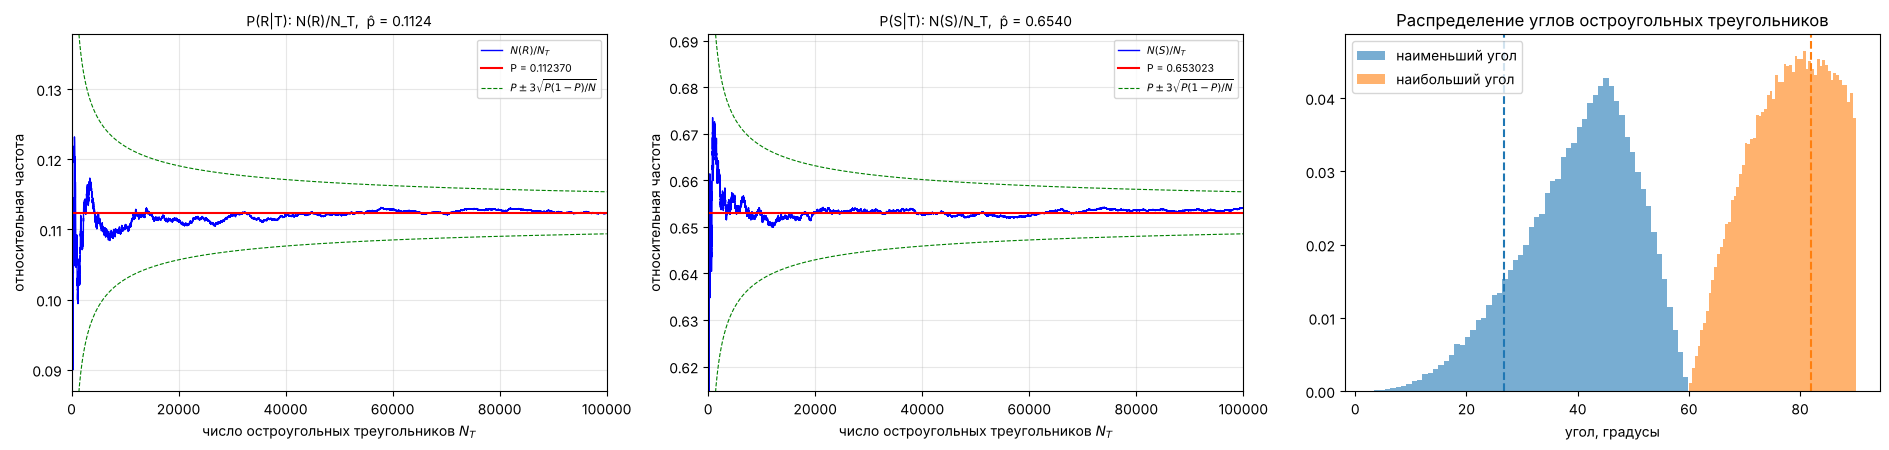

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(19, 4.6))
plot_frequency(axs[0], R, P_R_ref, f'P(R|T): N(R)/N_T,  p̂ = {R.mean():.4f}', label=r'$N(R)/N_T$')
plot_frequency(axs[1], S, P_S_ref, f'P(S|T): N(S)/N_T,  p̂ = {S.mean():.4f}', label=r'$N(S)/N_T$')
for ax in axs[:2]: ax.set_xlabel('число остроугольных треугольников $N_T$')
axs[2].hist(mn, bins=60, alpha=0.6, density=True, label='наименьший угол'); axs[2].hist(mx, bins=60, alpha=0.6, density=True, label='наибольший угол')
axs[2].axvline(26.7, color='tab:blue', ls='--'); axs[2].axvline(81.9, color='tab:orange', ls='--')
axs[2].set_xlabel('угол, градусы'); axs[2].legend(); axs[2].set_title('Распределение углов остроугольных треугольников')
plt.tight_layout(); plt.savefig('task_4_17.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
1) $\mathbb P(R|T)\approx0{,}11$; 2) $\mathbb P(S|T)\approx0{,}65$ (эталон по $2\cdot10^6$ треугольников: $0{,}112$ и $0{,}653$; с одним знаком после запятой — $0{,}1$ и $0{,}7$).